# 01 — Timers, loop overhead and clock domains of the H100 NVL

**Goal.** Every later measurement on this GPU turns a timer reading into a latency, a bandwidth or an ordering of events. This experiment measures the instruments themselves:

1. what it costs to read `%clock64`, `%clock` and `%globaltimer`;
2. how finely `%globaltimer` resolves time, and whether all SMs see the same `%globaltimer`;
3. what the loop around a dependent-load chain adds to each measured access;
4. how fast the SM, GPC, L2 and DRAM clocks actually run while the SM clock is locked;
5. what a `cudaEvent` pair and an empty kernel launch cost.

Without these numbers, a cycle count cannot be converted to time, and timer or loop overhead cannot be told apart from memory latency.

## Background

**Three clocks a kernel can read.**

| Timer | PTX | SASS | Counts | Scope |
|---|---|---|---|---|
| cycle counter | `mov.u64 %r, %clock64;` (32-bit: `%clock`) | `CS2R R, SR_CLOCKLO` (`CS2R.32` for `%clock`) | cycles of the SM that executes the instruction | one SM; values on different SMs are unrelated |
| global timer | `mov.u64 %r, %globaltimer;` | `CS2R R, SR_GLOBALTIMERLO` | nanoseconds | the whole GPU |
| CUDA events | `cudaEventRecord` / `cudaEventElapsedTime` | — | milliseconds between two points of a stream | the whole GPU, including host-side submission |

Intra-SM latencies are measured in SM cycles. `%globaltimer` orders events across SMs. Events time whole kernels.

**The dependent chain.** A latency is measured by making each access depend on the previous one, so that the accesses cannot overlap:

```
p = smem[p]   →   ld.shared.u32 p, [p];   →   LDS R13, [R13]
```

The chain sits in a loop that is partly unrolled. The loop's counter, compare and branch are extra instructions that may or may not be hidden behind the latency being measured. The end timestamp must also wait for the last access to return. Here the last loaded value is first consumed by an AND with a runtime zero, and only then is the clock read:

```
LOP3.LUT R17, R13, UR5, RZ, 0xc0, !PT   // waits for the last LDS (R13)
CS2R     R10, SR_CLOCKLO                // end timestamp
```

**The compiler is part of the measurement.** PTX is not what runs. `ptxas` deletes timer reads whose value is never used. It removes `mov.u32 p, p` and the then-empty loop around it. It fuses `add.u32 p, p, k; add.u32 p, p, k` into one `IMAD p, k, 2, p`. Every kernel below was therefore checked in SASS, and the forms that survive one-for-one were chosen:

- timer reads go into registers and are folded into a sink after each group of 32 reads;
- the "add" chain is `mad.lo.u32 p, p, 1, 0` with runtime operands, which is exactly one `IMAD` per step.

**Clock domains.** The SMs and GPCs, the L2 cache and the HBM controllers run on separate clocks. Nsight Compute reports each one as `<unit>__cycles_elapsed.avg.per_second`. In these runs only the graphics (SM) clock is locked, with `nvidia-smi -lgc 1635,1635`.

## Experimental setup

**Device and configuration.**
- NVIDIA H100 NVL: 132 SMs, 60 MiB L2, 94 GB HBM3 at 2619 MHz.
- Power limit 400 W, ECC on, MIG off.
- Driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`).
- SM clock locked at 1635 MHz with `nvidia-smi -lgc`. The memory clock is not locked.
- Every launch is followed by an NVML sample of the SM and memory clocks, the clock-event (throttle) reasons, power and temperatures. These samples fill the clock columns of each CSV row.
- A launch is flagged if a throttle reason is set or the SM clock reads more than 15 MHz below the lock.

**Kernels.**

| | What | Placement | Repetitions |
|---|---|---|---|
| K1 | 4 timer forms × 1024 reads (32 groups of 32 back-to-back reads) | 1 warp, 1 SM | 10 launches after 2 warm-ups, all 32 lanes recorded |
| K2a | one thread spins 2²⁰ reads of `%globaltimer`; at each change of value it stores (value, `%clock64`). All records are reduced exactly into histograms of the increments, whole-window totals, and windows of 1024 changes | 1 CTA per SM on all 132 SMs (200 KB shared memory per CTA; distinct `%smid` checked). 8 SMs spread over the `%smid` range measure; a second run (`k2all`) measures on all 132 SMs at once | 10 launches |
| K2b | 8 rounds per launch. In each round one of the 8 SMs writes a flag in global memory at a recorded `%globaltimer` time, and the other 131 SMs poll it and record `%globaltimer` when they see it. Each SM pair is measured in both directions | same as K2a | 10 launches |
| K3 | dependent chain of `ld.shared`, `mad.lo` ("add") or `mov` (ptxas deletes the `mov` chain and its loop: bare timed region); iters ∈ {256, 1024, 4096, 16384} × unroll ∈ {1, 4, 16} | 1 thread, 1 SM | 10 launches per point after 2 warm-ups |
| K4 | Nsight Compute clock counters on the K3 kernel and on a ~10 ms spin kernel on all SMs. Run once with ncu leaving our lock in place (`--clock-control none`) and once with ncu setting its own base clock (`--clock-control base`) | — | 5 profiled launches per kernel and mode |
| K5 | empty kernel `<<<1,32>>>`: 1000 launches each between its own event pair; 10 batches of 1000 back-to-back launches between one event pair; 1000 event pairs with nothing in between | — | as listed |

Every benchmark invocation is one run with its own run identifier. The tables below use the latest complete run of each benchmark. An earlier, complete set of runs from the same session is kept in the CSV files. Its K4 profile could not be exported, and its K2b used a single fixed writer. Its numbers agree with the runs shown here.

In [1]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

R = "results"
EXP = "01__timers_and_harness"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)

def q(s, p): return np.percentile(s, p)
def summary(s):
    s = pd.Series(s).astype(float)
    return pd.Series({"median": s.median(), "mean": s.mean(), "std": s.std(), "p5": q(s, 5), "p95": q(s, 95), "n": len(s)})

runs = pd.read_csv(f"{R}/{EXP}__runs.csv")
status = runs.groupby("run_id")["status"].agg(lambda s: "complete" if "complete" in set(s) else "partial")
cmd = runs.dropna(subset=["started_iso"]).set_index("run_id")["cmdline"]
clog = pd.read_csv(f"{R}/{EXP}__clock_log.csv")

def latest_complete(df, sub=None):
    """Rows of the latest complete run in df (optionally restricted to runs of one subcommand)."""
    ids = [r for r in df["run_id"].unique() if status.get(r) == "complete"]
    if sub: ids = [r for r in ids if re.search(rf"timers {sub}(\s|$)", cmd.get(r, ""))]
    rid = max(ids)
    return df[df["run_id"] == rid].copy(), rid

def bad_launches(rid, label_prefix):
    """(label, launch_idx) pairs whose post-launch clock sample shows a throttle reason or a clock below the lock."""
    c = clog[(clog.run_id == rid) & clog.label.str.startswith(label_prefix) & (clog.phase == "launch")]
    return c[(c.throttle == 1) | (c.below_lock == 1)][["label", "launch_idx"]]

In [2]:
# Device and fixed configuration, from the mandatory CSV columns and the clock log
first = clog.iloc[0]
dev = pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version],
    "driver": [first.driver_version], "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all samples)": [f"{clog.sm_clock_mhz.min()}–{clog.sm_clock_mhz.max()} MHz"],
    "memory clock (NVML)": [f"{clog.mem_clock_mhz.min()}–{clog.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{clog.power_w.min():.0f}–{clog.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{clog.gpu_temp_c.max()} / {clog.mem_temp_c.max()} °C"],
})
display(dev.T.rename(columns={0: ""}))

# Runs of this experiment (one run per benchmark invocation)
r = runs.dropna(subset=["started_iso"])[["run_id", "cmdline"]].copy()
r["benchmark"] = r.cmdline.str.extract(r"timers (\w+)")[0]
r["status"] = r.run_id.map(status)
display(r[["run_id", "benchmark", "status"]].reset_index(drop=True))

# Launches flagged by the clock samples (throttle reason or SM clock below the lock) and discarded launches
flag = clog[(clog.phase == "launch") & ((clog.throttle == 1) | (clog.below_lock == 1))]
disc = clog[clog.phase.str.startswith("discard")]
print(f"launches with a throttle reason or a clock below the lock: {len(flag)} "
      f"{ {k: int(v) for k, v in flag.label.value_counts().items()} }; launches discarded for placement/timeout: {len(disc)}")
print("throttle reasons seen in any sample:", sorted(clog.clocks_event_reasons_hex.unique()))

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all samples),1080–1635 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),75–114 W
GPU / HBM temperature max,34 / 36 °C


,run_id,benchmark,status
0,2026-10-23T19:12:36.942+00:00,clockcheck,complete
1,2026-10-23T19:12:39.527+00:00,k1,complete
2,2026-10-23T19:12:40.816+00:00,k2,complete
3,2026-10-23T19:12:46.511+00:00,k3,complete
4,2026-10-23T19:12:49.685+00:00,k5,complete
5,2026-10-23T19:12:58.756+00:00,k4,complete
6,2026-10-23T19:18:10.949+00:00,clockcheck,complete
7,2026-10-23T19:18:13.508+00:00,k1,complete
8,2026-10-23T19:18:14.753+00:00,k2,complete
9,2026-10-23T19:18:20.641+00:00,k2all,complete


launches with a throttle reason or a clock below the lock: 10 {'k4_base_k3': 5, 'k4_base_spin': 5}; launches discarded for placement/timeout: 0
throttle reasons seen in any sample: ['0x0000000000000000']


## Results

### K1 — cost of reading a timer

Each read costs **2 cycles** to issue, whether it is `%clock64`, `%clock` or `%globaltimer`. A `%clock64` + `%globaltimer` pair costs **4 cycles**. The values are identical in every launch and in all 32 lanes. This is the issue cost of back-to-back reads; the time until a read's value can be used is larger (see the polling loop in K2a).

In [3]:
k1, rid_k1 = latest_complete(pd.read_csv(f"{R}/01__timers__timer_cost.csv"), "k1")
tab = k1.groupby("timer").cycles_per_read.apply(summary).unstack()
tab = tab.loc[["clock64", "clock32", "globaltimer", "timers_pair"]]
display(tab[["median", "p5", "p95", "n"]])
lane_spread = k1.groupby(["launch_idx", "timer"]).cycles_per_read.agg(lambda s: s.max() - s.min()).max()
print(f"largest difference between the 32 lanes of one launch: {lane_spread:.4f} cycles/read")

,median,p5,p95,n
timer,,,,
clock64,2.0,2.0,2.0,320.0
clock32,2.0,2.0,2.0,320.0
globaltimer,2.0,2.0,2.0,320.0
timers_pair,4.0,4.0,4.0,320.0


largest difference between the 32 lanes of one launch: 0.0000 cycles/read


### K2a — resolution of `%globaltimer` and the SM clock it implies

`%globaltimer` advances in steps of exactly **32 ns**: every observed increment is 32 or 64 ns.

The polling loop (read, compare, store on change) takes **54 SM cycles ≈ 33 ns** per iteration, which is slightly longer than one tick. So 91.5 % of observed changes are one tick apart, and the 8.5 % that are two ticks apart are polls that straddled a tick. The occasional 95 and 99 cycle intervals are iterations that also had to store a record. The per-change cycle counts therefore describe the loop, not the timer. Over the whole ≈34 ms window, however, the ratio of `%clock64` cycles to `%globaltimer` nanoseconds is the SM clock, measured independently of NVML and ncu.

observed increments of %globaltimer between consecutive changes (all 8 SMs, 10 launches):


,fraction,count
delta_ns,,
32.0,0.915,7.210e+07
64.0,0.085,6.733e+06


SM cycles between consecutive observed changes:


count   fraction
delta_ns delta_cycles                      
32.0     54.0          6.706e+07  8.506e-01
         95.0          3.678e+06  4.665e-02
         99.0          1.364e+06  1.730e-02
64.0     54.0          6.726e+06  8.532e-02
         99.0          6.719e+03  8.523e-05

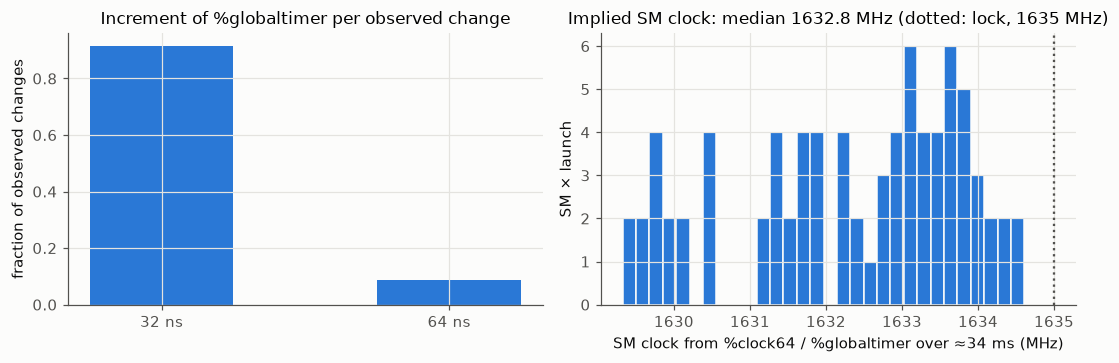

In [4]:
gr = pd.read_csv(f"{R}/01__timers__globaltimer_resolution.csv")
k2, rid_k2 = latest_complete(gr, "k2")          # 8 SMs (latest `k2` run; the `k2all` run is separate)
hist = k2[k2.kind == "delta_hist"]
tot = k2[k2.kind == "window_total"]
dn = hist.groupby("delta_ns")["count"].sum()
dc = hist.groupby(["delta_ns", "delta_cycles"])["count"].sum()
print("observed increments of %globaltimer between consecutive changes (all 8 SMs, 10 launches):")
display((dn / dn.sum()).rename("fraction").to_frame().assign(count=dn))
print("SM cycles between consecutive observed changes:")
display(dc.rename("count").to_frame().assign(fraction=lambda d: d["count"] / d["count"].sum()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(dn.index.astype(int).astype(str) + " ns", dn.values / dn.sum(), color=C1, width=0.5)
ax[0].set_ylabel("fraction of observed changes"); ax[0].set_title("Increment of %globaltimer per observed change")
mhz = tot.sm_mhz_from_globaltimer
ax[1].hist(mhz, bins=30, color=C1, edgecolor=SURF, linewidth=1)
ax[1].axvline(1635, color=INK2, ls=":", lw=1.5)
ax[1].set_xlabel("SM clock from %clock64 / %globaltimer over ≈34 ms (MHz)"); ax[1].set_ylabel("SM × launch")
ax[1].set_title(f"Implied SM clock: median {mhz.median():.1f} MHz (dotted: lock, 1635 MHz)")
fig.tight_layout(); plt.show()

launch_idx,0,1,2,3,4,5,6,7,8,9
smid,,,,,,,,,,
0,1631.12,1633.69,1631.56,1631.28,1631.86,1633.74,1631.41,1632.20,1631.68,1631.78
19,1633.58,1634.55,1633.66,1633.72,1634.05,1634.61,1633.72,1633.97,1633.84,1633.76
37,1629.33,1633.48,1629.55,1629.82,1630.19,1633.29,1630.50,1630.39,1629.87,1629.78
56,1632.78,1634.20,1632.90,1633.03,1633.42,1634.27,1632.98,1633.34,1633.10,1633.14
75,1631.94,1633.76,1631.94,1632.37,1632.79,1634.00,1632.19,1632.65,1632.44,1632.29
94,1629.33,1633.48,1629.55,1629.82,1630.19,1633.29,1630.51,1630.39,1629.87,1629.78
112,1632.78,1634.20,1632.90,1633.03,1633.42,1634.27,1632.98,1633.34,1633.09,1633.14
131,1631.12,1633.69,1631.56,1631.28,1631.86,1633.74,1631.41,1632.20,1631.68,1631.78


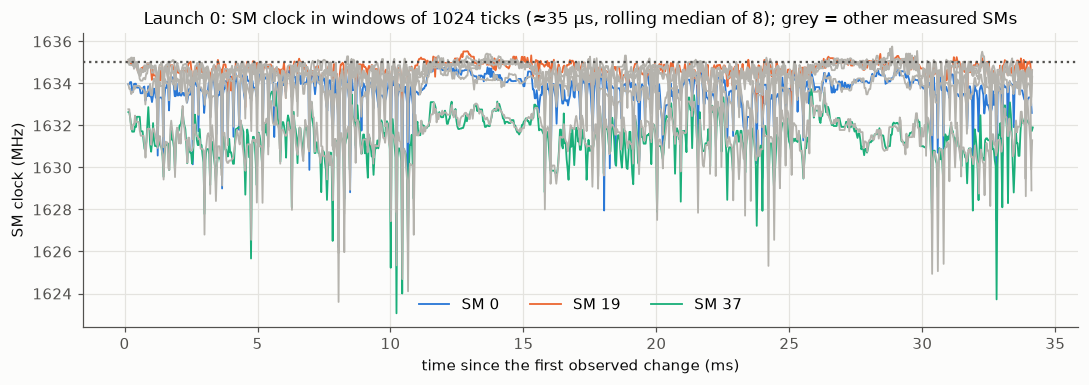

In [5]:
# Implied clock per SM and launch (whole 1M-read window)
piv = tot.pivot_table(index="smid", columns="launch_idx", values="sm_mhz_from_globaltimer")
display(piv.round(2))
tr, _ = latest_complete(pd.read_csv(f"{R}/01__timers__globaltimer_trace.csv"), "k2")
fig, ax = plt.subplots(figsize=(10, 3.6))
L = piv.mean().idxmin()   # the launch with the lowest mean clock
for i, (sm, g) in enumerate(tr[tr.launch_idx == L].groupby("smid")):
    ax.plot(g.start_ns / 1e6, g.sm_mhz_from_globaltimer.rolling(8, center=True).median(), lw=1.2,
            color=[C1, C2, C3][i % 3] if i < 3 else "#b5b3ad", label=f"SM {sm}" if i < 3 else None)
ax.axhline(1635, color=INK2, ls=":", lw=1.5)
ax.set_xlabel("time since the first observed change (ms)"); ax.set_ylabel("SM clock (MHz)")
ax.set_title(f"Launch {L}: SM clock in windows of 1024 ticks (≈35 µs, rolling median of 8); grey = other measured SMs")
ax.legend(frameon=False, ncol=3); fig.tight_layout(); plt.show()

8 clock groups; largest difference inside a group 0.0068 MHz; every pair of SMs from different groups differs by at least 0.974 MHz in some launch


,SMs,mean clock (MHz),%smid members
group,,,
A,16,1630.54,4 5 20 21 36 37 52 53 66 67 80 81 94 95 108 109
B,18,1632.27,12 13 28 29 44 45 60 61 74 75 88 89 102 103 11...
C,12,1632.29,0 1 16 17 32 33 48 49 124 125 130 131
D,18,1632.80,8 9 24 25 40 41 56 57 70 71 84 85 98 99 112 11...
E,18,1633.08,10 11 26 27 42 43 58 59 72 73 86 87 100 101 11...
F,16,1634.26,2 3 18 19 34 35 50 51 64 65 78 79 92 93 106 107
G,18,1634.41,14 15 30 31 46 47 62 63 76 77 90 91 104 105 11...
H,16,1634.78,6 7 22 23 38 39 54 55 68 69 82 83 96 97 110 111


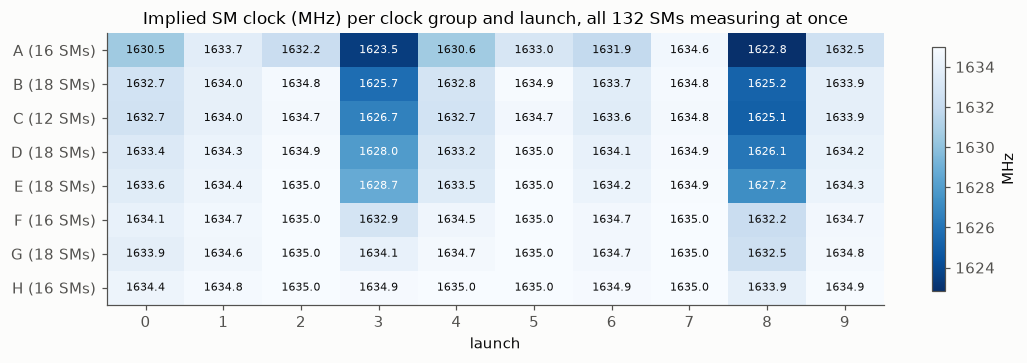

In [6]:
# All 132 SMs (k2all): SMs whose implied clock agrees in every launch form one clock group
a, rid_all = latest_complete(gr, "k2all")
a = a[a.kind == "window_total"]
P = a.pivot_table(index="smid", columns="launch_idx", values="sm_mhz_from_globaltimer")
D = np.abs(P.values[:, None, :] - P.values[None, :, :]).max(axis=2)   # largest per-launch difference between two SMs
lab = -np.ones(len(P), int); g = 0
for i in range(len(P)):                      # connected components of "differs by < 0.1 MHz in every launch"
    if lab[i] >= 0: continue
    stack, lab[i] = [i], g
    while stack:
        j = stack.pop()
        for k in np.where((D[j] < 0.1) & (lab < 0))[0]: lab[k] = g; stack.append(k)
    g += 1
grp = pd.Series(lab, index=P.index, name="group")
order = P.groupby(grp).mean().mean(axis=1).sort_values().index   # name groups A.. by mean clock
grp = grp.map({old: chr(ord("A") + i) for i, old in enumerate(order)})
iu = np.triu_indices(len(P), 1)
same_grp = grp.values[iu[0]] == grp.values[iu[1]]
print(f"{grp.nunique()} clock groups; largest difference inside a group {D[iu][same_grp].max():.4f} MHz; "
      f"every pair of SMs from different groups differs by at least {D[iu][~same_grp].min():.3f} MHz in some launch")
G = P.groupby(grp).mean()
members = grp.reset_index().groupby("group").smid.apply(lambda s: " ".join(map(str, sorted(s))))
display(pd.DataFrame({"SMs": grp.value_counts().sort_index(), "mean clock (MHz)": G.mean(axis=1).round(2),
                      "%smid members": members}))
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(G.values, aspect="auto", cmap="Blues_r", vmin=G.values.min(), vmax=1635)
ax.set_yticks(range(len(G)), [f"{n} ({(grp == n).sum()} SMs)" for n in G.index]); ax.set_xticks(range(G.shape[1]))
ax.set_xlabel("launch"); ax.grid(False)
for (i, j), v in np.ndenumerate(G.values):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if v < (G.values.min() + 1635) / 2 else INK)
ax.set_title("Implied SM clock (MHz) per clock group and launch, all 132 SMs measuring at once")
fig.colorbar(im, ax=ax, shrink=0.9, label="MHz"); fig.tight_layout(); plt.show()

,median,mean,std,p5,p95,n
observation delay (ns),352.0,335.588,66.432,224.0,448.0,10480.0


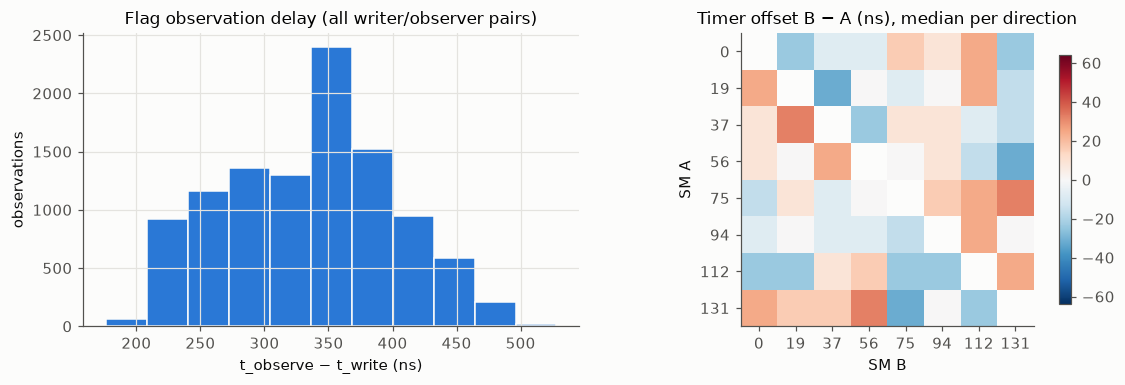

pairwise offsets: median |offset| 16.0 ns, max |offset| 32.0 ns


In [7]:
# K2b: flag observation delay and pairwise timer offsets
sk, rid_sk = latest_complete(pd.read_csv(f"{R}/01__timers__globaltimer_skew.csv"), "k2")
display(sk.skew_ns.pipe(summary).to_frame("observation delay (ns)").T)
W = sorted(sk.writer_smid.unique())
d = sk[sk.observer_smid.isin(W)].groupby(["writer_smid", "observer_smid"]).skew_ns.median().unstack()
off = ((d - d.T) / 2).loc[W, W]       # (d(A→B) − d(B→A)) / 2 = offset(B) − offset(A) if propagation is symmetric
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].hist(sk.skew_ns, bins=np.arange(sk.skew_ns.min() - 16, sk.skew_ns.max() + 48, 32), color=C1, edgecolor=SURF)
ax[0].set_xlabel("t_observe − t_write (ns)"); ax[0].set_ylabel("observations")
ax[0].set_title("Flag observation delay (all writer/observer pairs)")
im = ax[1].imshow(off.values, cmap="RdBu_r", vmin=-64, vmax=64)
ax[1].set_xticks(range(len(W)), W); ax[1].set_yticks(range(len(W)), W)
ax[1].set_xlabel("SM B"); ax[1].set_ylabel("SM A"); ax[1].grid(False)
ax[1].set_title("Timer offset B − A (ns), median per direction")
fig.colorbar(im, ax=ax[1], shrink=0.85); fig.tight_layout(); plt.show()
print(f"pairwise offsets: median |offset| {np.nanmedian(np.abs(off.values[~np.eye(len(W), dtype=bool)])):.1f} ns, "
      f"max |offset| {np.nanmax(np.abs(off.values)):.1f} ns")

### K3 — loop overhead and the dependent `ld.shared` chain

The table and figure give the median cycles per iteration. Every launch of a configuration took exactly the same number of cycles. The linear fit below splits each configuration into a cost per step (slope over `iters`) and a fixed cost of the timed region (intercept). It fits the data with zero residual.

The three variants measure different things:
- `mov` contains no loop after compilation. `ptxas` deletes the `mov.u32 p, p` moves and then the empty loop, so only the two clock reads remain. The variant measures the bare timed region: 66 cycles in every configuration (slope 0). Its "cycles per iteration" is just 66 / `iters` (0.258 at 256 down to 0.004 at 16 384) and says nothing about per-iteration loop overhead.
- `add` (`mad.lo`, one dependent `IMAD` of 4 cycles per step) keeps the loop. It is the only variant that shows the per-iteration cost of the loop: 29 cycles per outer iteration at unroll 1 and 4, 71 = 16 × 4 + 7 at unroll 16.
- `ld_shared` is the dependent shared-memory load chain; its loop control is hidden behind the 23-cycle loads from unroll 4 on.

iters              256     1024    4096    16384
variant   unroll                                
add       1       29.742  29.186  29.046  29.012
          4        7.992   7.436   7.296   7.262
          16       5.188   4.625   4.484   4.449
ld_shared 1       30.644  30.161  30.040  30.010
          4       23.695  23.174  23.044  23.011
          16      23.695  23.174  23.044  23.011
mov       1        0.258   0.064   0.016   0.004
          4        0.258   0.064   0.016   0.004
          16       0.258   0.064   0.016   0.004

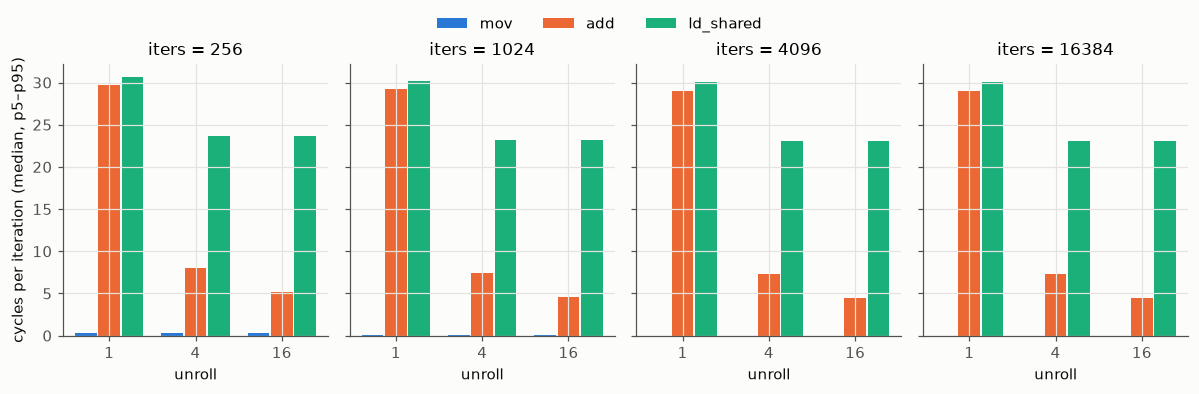

In [8]:
lo, rid_k3 = latest_complete(pd.read_csv(f"{R}/01__timers__loop_overhead.csv"), "k3")
t3 = lo.groupby(["variant", "unroll", "iters"]).cycles_per_iter.median().unstack("iters")
display(t3.round(3))
fig, axs = plt.subplots(1, 4, figsize=(11, 3.4), sharey=True)
cols = {"mov": C1, "add": C2, "ld_shared": C3}
for ax, it in zip(axs, sorted(lo.iters.unique())):
    sub = lo[lo.iters == it].groupby(["variant", "unroll"]).cycles_per_iter
    med, p5, p95 = sub.median(), sub.quantile(0.05), sub.quantile(0.95)
    x = np.arange(3)
    for j, v in enumerate(["mov", "add", "ld_shared"]):
        m = med[v].reindex([1, 4, 16]).values
        err = [m - p5[v].reindex([1, 4, 16]).values, p95[v].reindex([1, 4, 16]).values - m]
        ax.bar(x + (j - 1) * 0.27, m, 0.25, color=cols[v], label=v if it == 256 else None, yerr=err, ecolor=INK2)
    ax.set_xticks(x, ["1", "4", "16"]); ax.set_xlabel("unroll"); ax.set_title(f"iters = {it}")
axs[0].set_ylabel("cycles per iteration (median, p5–p95)")
fig.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(); plt.show()

In [9]:
# Linear model per (variant, unroll): total_cycles = fixed + slope * iters  (least squares over all launches)
fit = []
for (v, u), g in lo.groupby(["variant", "unroll"]):
    slope, fixed = np.polyfit(g.iters, g.total_cycles, 1)
    resid = g.total_cycles - (fixed + slope * g.iters)
    fit.append(dict(variant=v, unroll=u, slope_cycles_per_step=slope, fixed_cycles=fixed,
                    cycles_per_outer_iteration=slope * u, max_abs_residual_cycles=resid.abs().max()))
fit = pd.DataFrame(fit).set_index(["variant", "unroll"])
display(fit.round(3))
dflt = lo[(lo.unroll == 16) & (lo.iters == 4096)].groupby("variant").cycles_per_iter.median()
print(f"default configuration (unroll 16, iters 4096): ld_shared {dflt['ld_shared']:.3f}, "
      f"mov {dflt['mov']:.3f} (= 66-cycle bare timed region / 4096), "
      f"ld_shared − mov = {dflt['ld_shared'] - dflt['mov']:.3f} cycles per load")

slope_cycles_per_step  fixed_cycles  \
variant   unroll                                        
add       1                      29.000         190.0   
          4                       7.250         190.0   
          16                      4.437         192.0   
ld_shared 1                      30.000         165.0   
          4                      23.000         178.0   
          16                     23.000         178.0   
mov       1                       0.000          66.0   
          4                       0.000          66.0   
          16                      0.000          66.0   

                  cycles_per_outer_iteration  max_abs_residual_cycles  
variant   unroll                                                       
add       1                             29.0                      0.0  
          4                             29.0                      0.0  
          16                            71.0                      0.0  
ld_shared 1                             30.0                      0.0  
          4                             92.0                      0.0  
          16                           368.0                      0.0  
mov       1                              0.0                      0.0  
          4                              0.0                      0.0  
          16                             0.0                      0.0

default configuration (unroll 16, iters 4096): ld_shared 23.044, mov 0.016 (= 66-cycle bare timed region / 4096), ld_shared − mov = 23.027 cycles per load


In [10]:
# SASS of the timed region of the ld.shared chain (unroll 16), from results/sass/timers.sass
txt = open(f"{R}/sass/timers.sass").read()
fn = txt.split("Function : _Z7k3_loopILi2ELi16E")[1].split("Function :")[0]
lines = [re.sub(r"\s*/\*[0-9a-f]{16}\*/", "", l).strip() for l in fn.splitlines() if re.match(r"\s+/\*[0-9a-f]{4}\*/", l)]
i0 = next(i for i, l in enumerate(lines) if "SR_CLOCKLO" in l)
i1 = next(i for i, l in enumerate(lines) if "SR_CLOCKLO" in l and i > i0)
sel = lines[i0:i1 + 1]
keep = [l for l in sel if re.search(r"LDS|UIADD3|ISETP\.LE|BRA|CS2R|LOP3", l)]
print("\n".join(keep[:6] + ["   ... (16 dependent LDS per iteration) ..."] + keep[-6:]))

/*0160*/                   CS2R R2, SR_CLOCKLO ;                                   /* 0x0000000000027805 */
/*01e0*/              @!P0 BRA 0x370 ;                                             /* 0x0000000000608947 */
/*0240*/                   LDS R13, [R13] ;                                        /* 0x000000000d0d7984 */
/*0250*/                   UIADD3 UR4, UR4, 0x1, URZ ;                             /* 0x0000000104047890 */
/*0260*/                   ISETP.LE.AND P0, PT, R0, UR4, PT ;                      /* 0x0000000400007c0c */
/*0270*/                   LDS R4, [R13] ;                                         /* 0x000000000d047984 */
   ... (16 dependent LDS per iteration) ...
/*0330*/                   LDS R10, [R9] ;                                         /* 0x00000000090a7984 */
/*0340*/                   LDS R10, [R10] ;                                        /* 0x000000000a0a7984 */
/*0350*/                   LDS R13, [R10] ;                                        /* 0x0000

### K4 — clock domains (Nsight Compute)

Median over the 5 profiled launches per kernel. `none` leaves the SM clock locked at 1635 MHz; `base` lets Nsight Compute set its own base clocks for the duration of profiling.

In [11]:
cd_ = pd.read_csv(f"{R}/01__timers__clock_domains.csv")
latest = cd_.groupby("clock_control").run_id.max()
cd_ = cd_[cd_.run_id.isin(latest.values)]
t4 = cd_.groupby(["clock_control", "kernel"])[["sm_hz", "gpc_hz", "lts_hz", "dram_hz", "lts_over_sm"]].median()
t4[["sm_hz", "gpc_hz", "lts_hz", "dram_hz"]] /= 1e6
display(t4.rename(columns={"sm_hz": "SM MHz", "gpc_hz": "GPC MHz", "lts_hz": "L2 MHz", "dram_hz": "DRAM MHz",
                           "lts_over_sm": "L2/SM"}).round(4))
comp = pd.DataFrame({
    "nvidia-smi / NVML (during the runs)": [clog[clog.run_id.isin([rid_k2])].sm_clock_mhz.median()],
    "%clock64 / %globaltimer (K2, median over SMs × launches)": [tot.sm_mhz_from_globaltimer.median()],
    "ncu sm__cycles_elapsed.avg.per_second (lock, median)": [cd_[cd_.clock_control == "none"].sm_hz.median() / 1e6],
    "ncu, --clock-control base (median)": [cd_[cd_.clock_control == "base"].sm_hz.median() / 1e6],
}, index=["SM clock (MHz)"]).T
display(comp.round(2))

SM MHz   GPC MHz    L2 MHz  DRAM MHz  L2/SM
clock_control kernel                                                
base          k3_loop  1075.290  1075.082  1214.826  2618.593  1.130
              k4_spin  1075.061  1074.846  1214.997  2618.992  1.130
none          k3_loop  1629.858  1629.793  1556.667  2618.729  0.955
              k4_spin  1633.456  1633.440  1555.289  2618.991  0.952

,SM clock (MHz)
nvidia-smi / NVML (during the runs),1635.00
"%clock64 / %globaltimer (K2, median over SMs × launches)",1632.78
"ncu sm__cycles_elapsed.avg.per_second (lock, median)",1631.66
"ncu, --clock-control base (median)",1075.07


In [12]:
# Unit counts implied by the .sum counters (sum over units / per-unit rate / kernel duration)
raw = pd.read_csv(f"{R}/01__timers__ncu_clock_domains_none.csv")
raw = raw[raw.run_id == latest["none"]]
t = raw["gpu__time_duration.sum"].astype(float) * 1e-9
units = pd.DataFrame({
    "GPC units": raw["gpc__cycles_elapsed.sum"].astype(float) / raw["gpc__cycles_elapsed.avg.per_second"].astype(float) / t,
    "SM units": raw["sm__cycles_elapsed.sum"].astype(float) / raw["sm__cycles_elapsed.avg.per_second"].astype(float) / t,
})
display(units.describe().loc[["min", "max"]].round(2))
fin = clog[clog.label == "after_k4_base"]
print(f"SM clock reported after the --clock-control base profiling run: {fin.sm_clock_mhz.tolist()} MHz")

,GPC units,SM units
min,8.0,132.0
max,8.0,132.0


SM clock reported after the --clock-control base profiling run: [1635] MHz


### K5 — cudaEvent and launch floor

,median,mean,std,p5,p95,n
mode,,,,,,
empty_pair,3.904,4.322,10.976,3.712,4.256,1000.0
single,12.128,12.674,2.255,11.776,14.240,1000.0
batch,7.918,8.316,1.881,6.844,11.294,10.0


,median,mean,std,p5,p95,n
host enqueue µs/launch (batch),7.906,8.303,1.877,6.838,11.272,10.0


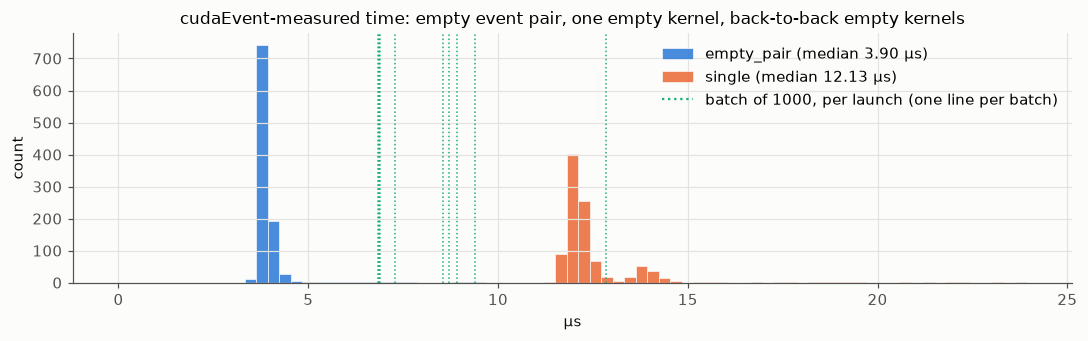

In [13]:
ef, rid_k5 = latest_complete(pd.read_csv(f"{R}/01__timers__event_floor.csv"), "k5")
t5 = ef.groupby("mode").us_per_launch.apply(summary).unstack()
display(t5.loc[["empty_pair", "single", "batch"]])
display(ef[ef["mode"] == "batch"].host_api_us_per_launch.pipe(summary).to_frame("host enqueue µs/launch (batch)").T)
fig, ax = plt.subplots(figsize=(10, 3.2))
for m, c in [("empty_pair", C1), ("single", C2)]:
    v = ef[ef["mode"] == m].us_per_launch
    ax.hist(v, bins=np.linspace(0, np.percentile(ef[ef["mode"] != "batch"].us_per_launch, 99.5), 80), color=c,
            alpha=0.85, label=f"{m} (median {v.median():.2f} µs)", edgecolor=SURF, linewidth=0.5)
for v in ef[ef["mode"] == "batch"].us_per_launch:
    ax.axvline(v, color=C3, lw=1, ls=":")
ax.plot([], [], color=C3, ls=":", label="batch of 1000, per launch (one line per batch)")
ax.set_xlabel("µs"); ax.set_ylabel("count"); ax.legend(frameon=False)
ax.set_title("cudaEvent-measured time: empty event pair, one empty kernel, back-to-back empty kernels")
fig.tight_layout(); plt.show()

## Insights

- **Reading a timer is cheap and deterministic.** `%clock64`, `%clock` and `%globaltimer` each issue in 2 cycles, so a `%clock64`/`%globaltimer` pair costs 4 cycles. A `%globaltimer` value, however, is only usable some tens of cycles later: a poll loop around it runs at 54 cycles per iteration.
- **`%globaltimer` has a 32 ns tick (≈52 SM cycles at 1635 MHz) and is consistent across SMs.** Measured in both directions, the timer offsets between pairs of SMs are at most one tick. The one-way observation delay of a flag in global memory is 224–448 ns (p5–p95, median 352 ns). That delay is propagation through the memory system plus the polling period, not timer skew. `%globaltimer` is therefore suitable for ordering events that are more than ~100 ns apart, and not for anything shorter.
- **The dependent `ld.shared` latency is 23 cycles on this GPU.** It is exactly 23.000 cycles per load at unroll 4 and 16, independent of `iters`. With a non-unrolled loop each iteration takes 30 cycles, because the loop's counter, compare and taken branch need about 29–30 cycles per iteration and cannot fully hide behind a single 23-cycle load. With a short-latency body (dependent `IMAD`, 4 cycles) the loop needs 29 cycles per iteration at unroll 1 and 4, and 16 × 4 + 7 = 71 cycles at unroll 16. Wherever a loop around a dependent chain is visible, its control adds 7 cycles per iteration on top of the chain.
- **Default for later experiments: unroll 16, `iters` = 4096.** With chains of ≥ 23 cycles per step, the loop control is entirely hidden. What remains is the fixed cost of the timed region (66 cycles bare, 165–192 cycles with the loop prologue), i.e. ≤ 0.05 cycles per access at 4096 iterations. The `mov` variant measures only the bare part of it: `ptxas` deletes its `mov.u32 p, p` moves and then the empty loop, so it times the two clock reads alone (66 cycles at every configuration, 66 / 4096 = 0.016 cycles per iteration at the default). It contains no loop and therefore no per-iteration overhead; the per-iteration cost of the loop is visible only through the `mad.lo` variant (7 cycles per iteration on top of a dependent chain, see above). For exact numbers, take the slope between two `iters` values; it cancels the fixed cost.
- **The locked SM clock is not uniform.** NVML reports exactly 1635 MHz throughout, with no throttle reason. But the cycles counted by the SMs per nanosecond of `%globaltimer` show 1622.8–1635.0 MHz per launch, and ncu's average SM clock shows 1627.5–1634.6 MHz. Both vary from launch to launch.
- **The 132 SMs fall into 8 clock groups of 16, 18, 12, 18, 18, 16, 18 and 16 SMs.** SMs in a group count identical cycles (within 0.007 MHz over 34 ms), while different groups differ by up to 11.4 MHz in the same launch (spread between the slowest and fastest group: 0.4–11.4 MHz depending on the launch). Each group consists of `%smid` pairs (2k, 2k+1), interleaved across groups. Nsight Compute counts 8 GPC clock units. This suggests one independently adjusted clock per GPC. The membership table is a candidate SM→GPC map; it should be confirmed by cluster co-scheduling. A consequence for all later work: per-SM cycle counts of different GPCs can disagree by up to 0.7 % over the same wall-clock interval. Cycle→time conversions should use the clock measured in the same run, not the nominal 1635 MHz.
- **L2 runs on its own clock, ≈1556 MHz, unaffected by the SM lock.** L2/SM is **0.951–0.956** (median ≈ 0.954) at our lock. With ncu's `--clock-control base`, the SM drops to 1075 MHz and the L2 to 1215 MHz (L2/SM = 1.13), so cycle counts that cross into L2 depend on how the clocks were controlled. DRAM stays at 2619 MHz in both modes. After the base-clock profiling run, our lock was back in place (NVML 1635 MHz).
- **Launch cost is bounded by the host here.** In back-to-back launches, the event-measured time per empty kernel (median 7.9 µs, 6.8–12.9 µs per batch) equals the host-side time to enqueue it to within 0.03 µs. The GPU waits for the CPU, so this is the throughput of the launch API on this host, not of the GPU front end. An empty event pair already measures 3.9 µs, and an event pair around a single empty kernel 12.1 µs. Event timing of kernels shorter than ~20 µs is therefore dominated by host submission. Launch-overhead studies on this machine need GPU-side timestamps or pre-built launch sequences, not per-launch event pairs.
- **Limitations.**
  - K2a observes a tick only when a poll happens to cross it, so the 32 ns resolution is established from the increments' values, not from the polling rate.
  - K2b's pairwise offsets assume equal propagation time in both directions.
  - ncu's `.sum` clock counters are available only as totals here, so the per-GPC clocks above come from `%clock64`, not from ncu.